In [32]:
# Walk up to repo root (identified by README.md)
.root <- getwd()
while (!file.exists(file.path(.root, 'README.md')) && dirname(.root) != .root)
  .root <- dirname(.root)
setwd(.root)
rm(.root)

suppressPackageStartupMessages({
  library(tidyverse)
  library(data.table)
  library(arrow)
  library(ggthemes)
  library(scales)
  library(patchwork)
})

options(repr.plot.width = 14, repr.plot.height = 8)

BASE_THEME <- theme_fivethirtyeight() +
  theme(
    axis.title        = element_text(size = 14),
    axis.text         = element_text(size = 13),
    panel.background  = element_rect(fill = "white", color = NA),
    plot.background   = element_rect(fill = "white", color = NA),
    legend.background = element_rect(fill = "white", color = NA),
    legend.text       = element_text(size = 12),
    legend.title      = element_text(size = 13),
    strip.text        = element_text(size = 14, face = "bold"),
    plot.title        = element_text(size = 20, face = "bold"),
    plot.subtitle     = element_text(size = 13)
  )
theme_set(BASE_THEME)

COMMIT_MS  <- 150

PITCH_NAMES <- c(
  FF = "4-Seam",    SI = "Sinker",    FC = "Cutter",
  CH = "Changeup",  FS = "Splitter",
  SL = "Slider",    CU = "Curveball", ST = "Sweeper",   KC = "Knuckle-curve"
)

PITCH_COLORS <- c(
  FF = "#d62728", SI = "#ff7f0e", FC = "#e377c2",
  CH = "#2ca02c", FS = "#17becf",
  SL = "#bcbd22", CU = "#1f77b4", ST = "#9467bd", KC = "#8c564b"
)

In [33]:
pc_sample    <- read_csv("data/viz_cache/pc_sample.csv",     show_col_types = FALSE) |>
  mutate(pitch_name = factor(PITCH_NAMES[pitch_type], levels = unname(PITCH_NAMES)))
pc_deception <- read_csv("data/viz_cache/pc_deception.csv",  show_col_types = FALSE) |>
  mutate(pitch_name = factor(pitch_name, levels = unname(PITCH_NAMES)))
pc_sens      <- read_csv("data/viz_cache/pc_sensitivity.csv", show_col_types = FALSE) |>
  mutate(pitch_name = factor(pitch_name, levels = unname(PITCH_NAMES)))
pc_count_dev <- read_csv("data/viz_cache/pc_count_dev.csv",  show_col_types = FALSE)

cat(sprintf(
  "Cache loaded | pc_sample: %s rows | pitch types: %s\n",
  formatC(nrow(pc_sample), format = "d", big.mark = ","),
  paste(sort(unique(pc_sample$pitch_type)), collapse = ", ")
))

Cache loaded | pc_sample: 30,000 rows | pitch types: CH, CU, FC, FF, FS, KC, SI, SL, ST


## Post-Commit Deviation Distributions

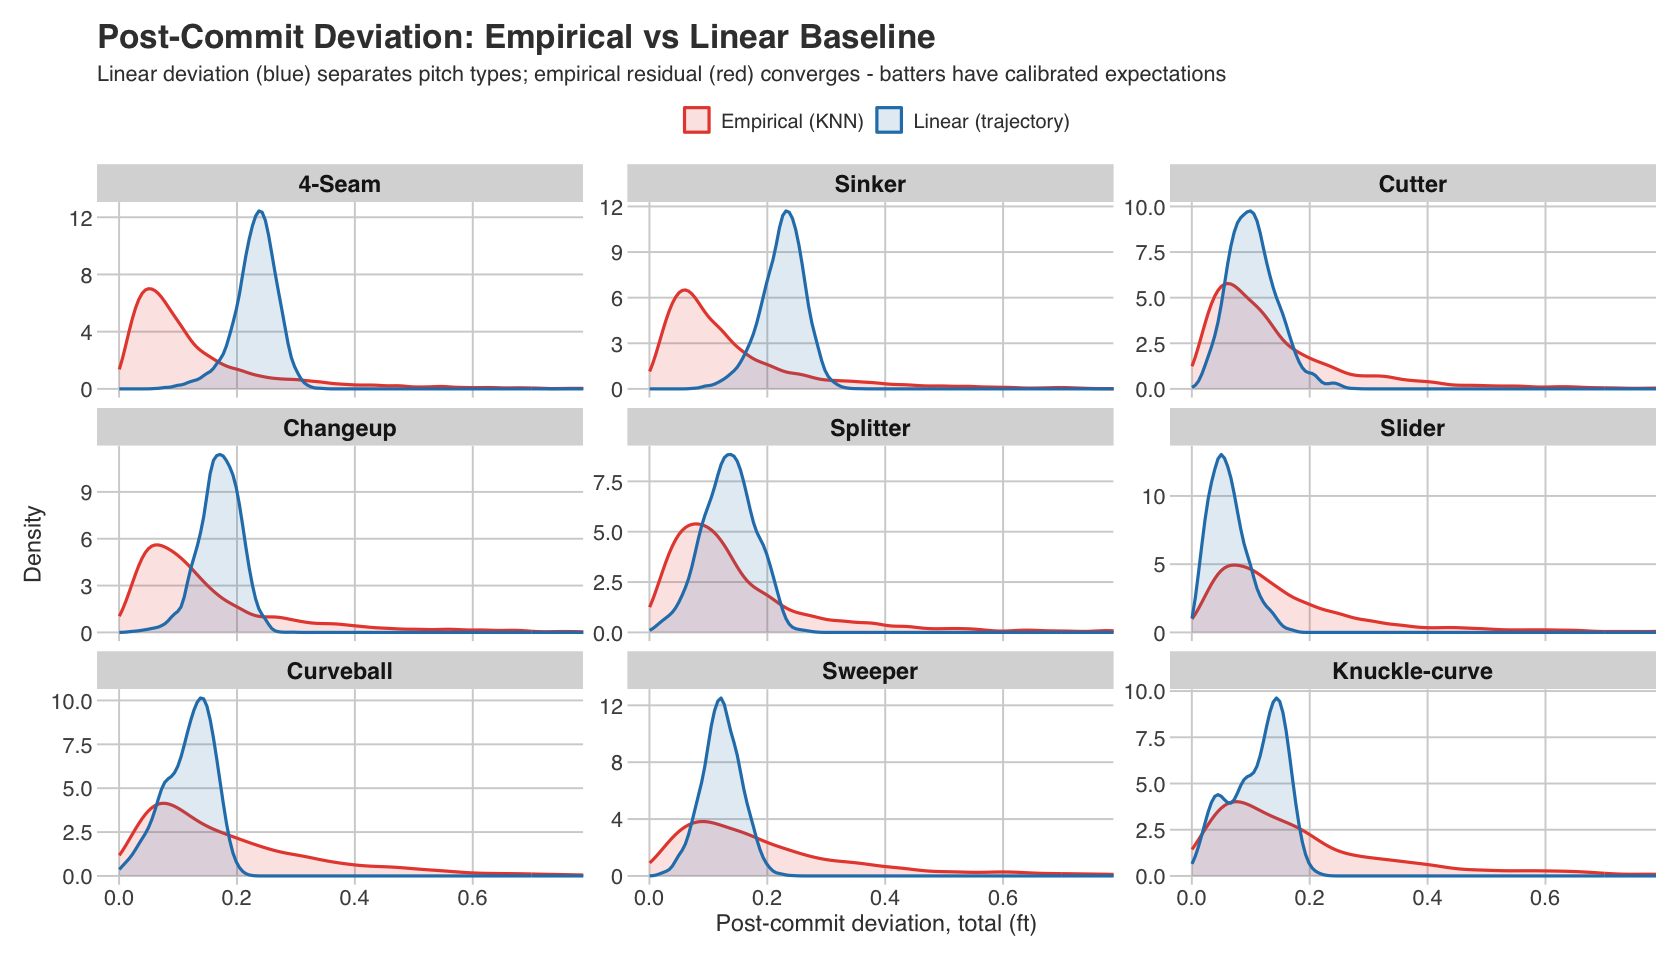

In [34]:
pc_sample |>
  pivot_longer(
    cols      = c(emp_dev_total, lin_dev_total),
    names_to  = "baseline",
    values_to = "dev_total"
  ) |>
  mutate(baseline = recode(baseline,
    emp_dev_total = "Empirical (KNN)",
    lin_dev_total = "Linear (trajectory)"
  )) |>
  ggplot(aes(x = dev_total, color = baseline, fill = baseline)) +
  geom_density(alpha = 0.15, linewidth = 0.9) +
  facet_wrap(~ pitch_name, nrow = 3, scales = "free_y") +
  coord_cartesian(xlim = c(0, 0.75)) +
  scale_color_manual(values = c("Empirical (KNN)" = "#e74c3c", "Linear (trajectory)" = "#2980b9"),
                     name = NULL) +
  scale_fill_manual(values  = c("Empirical (KNN)" = "#e74c3c", "Linear (trajectory)" = "#2980b9"),
                    name = NULL) +
  labs(
    title    = "Post-Commit Deviation: Empirical vs Linear Baseline",
    subtitle = "Linear deviation (blue) separates pitch types; empirical residual (red) converges - batters have calibrated expectations",
    x        = "Post-commit deviation, total (ft)",
    y        = "Density"
  ) +
  theme(legend.position = "top")

## Empirical vs. Linear Baseline

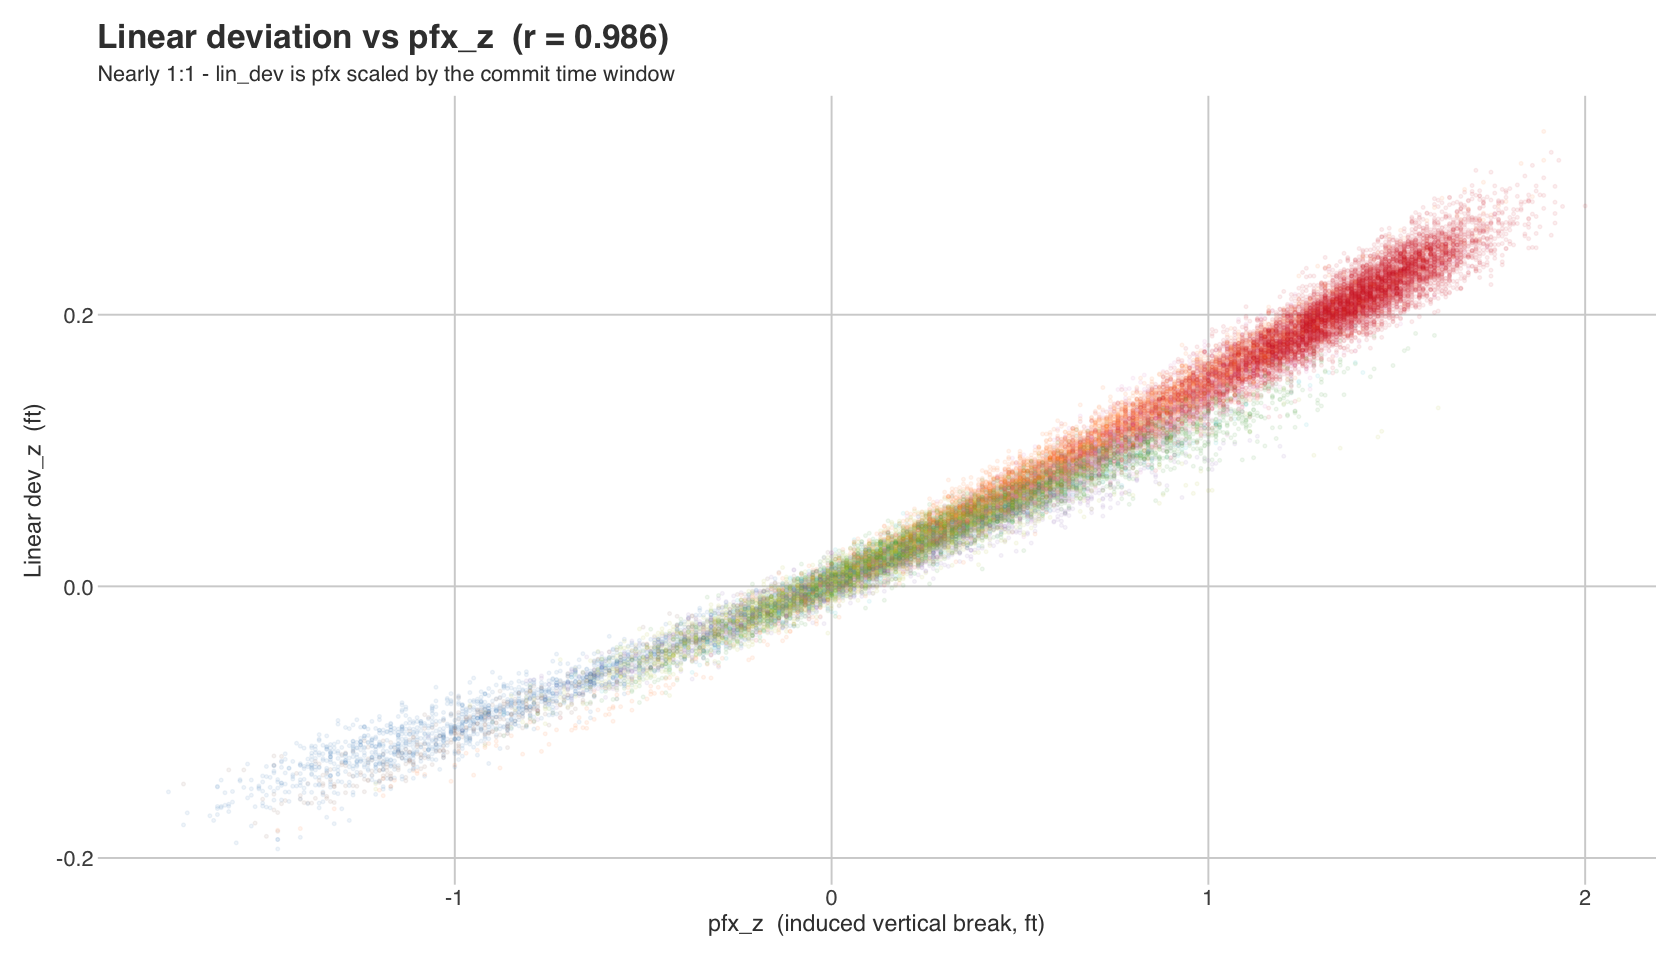

In [35]:
r_lin <- cor(pc_sample$pfx_z, pc_sample$pc150_dev_z, use = "complete.obs")

ggplot(pc_sample, aes(x = pfx_z, y = pc150_dev_z, color = pitch_type)) +
  geom_point(alpha = 0.07, size = 0.7, show.legend = FALSE) +
  scale_color_manual(values = PITCH_COLORS) +
  labs(
    title    = sprintf("Linear deviation vs pfx_z  (r = %.3f)", r_lin),
    subtitle = "Nearly 1:1 - lin_dev is pfx scaled by the commit time window",
    x        = "pfx_z  (induced vertical break, ft)",
    y        = "Linear dev_z  (ft)"
  )

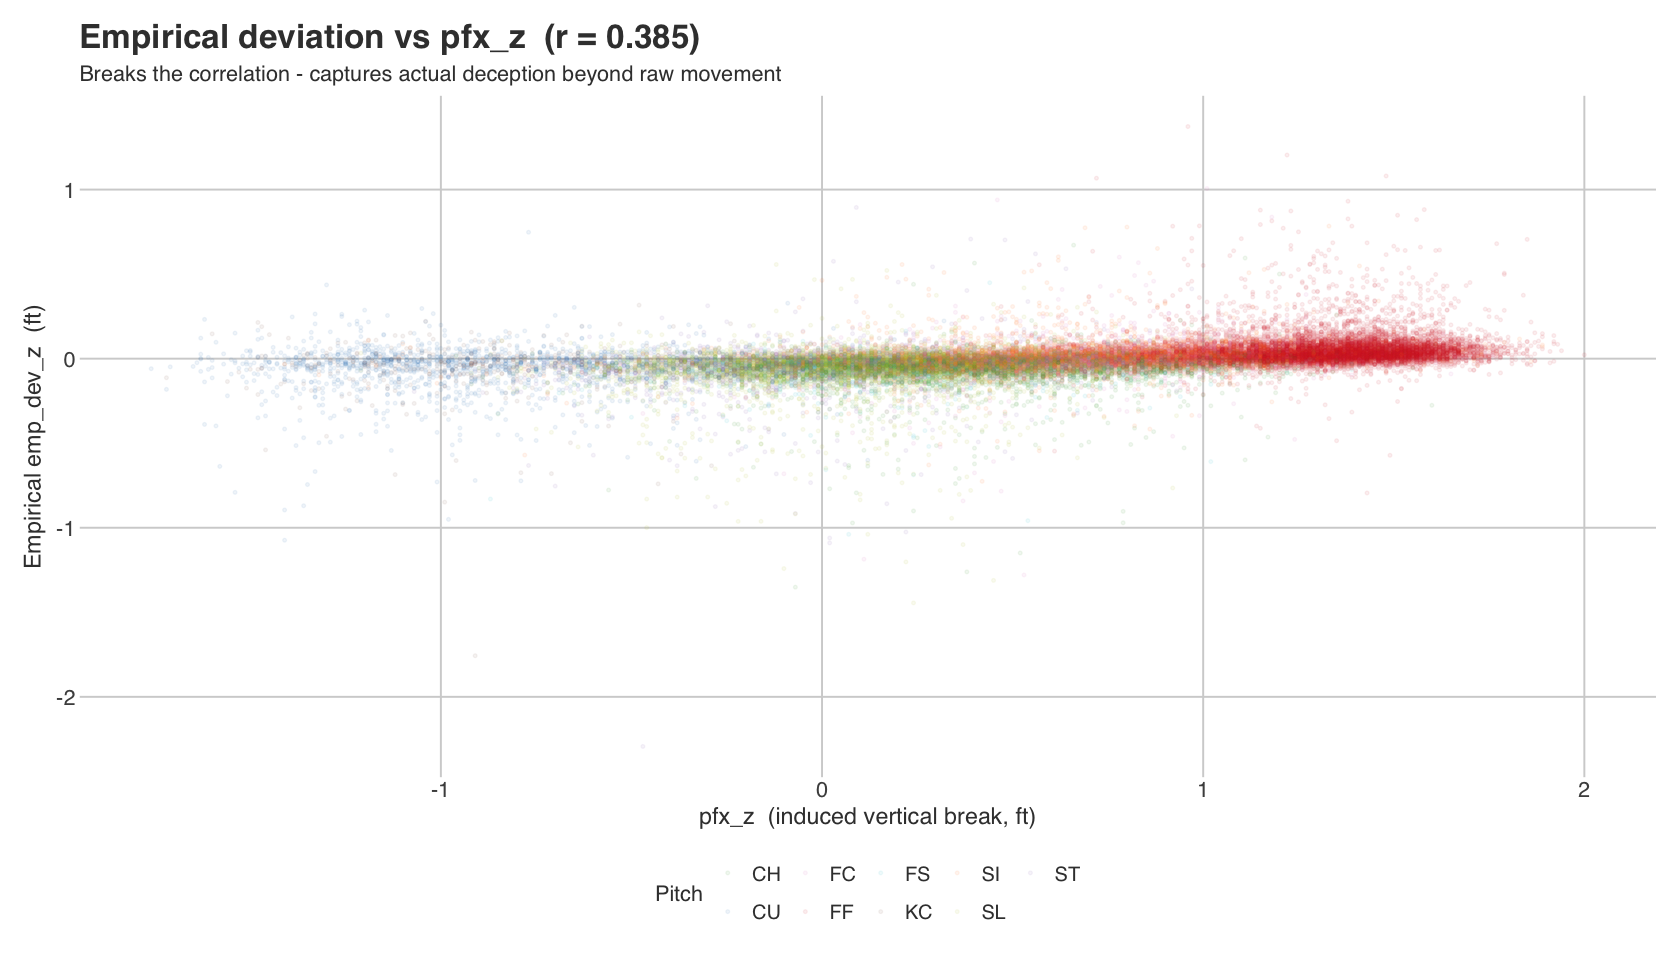

In [36]:
r_emp <- cor(pc_sample$pfx_z, pc_sample$pc150_emp_dev_z, use = "complete.obs")

ggplot(pc_sample, aes(x = pfx_z, y = pc150_emp_dev_z, color = pitch_type)) +
  geom_point(alpha = 0.07, size = 0.7) +
  scale_color_manual(values = PITCH_COLORS, name = "Pitch") +
  labs(
    title    = sprintf("Empirical deviation vs pfx_z  (r = %.3f)", r_emp),
    subtitle = "Breaks the correlation - captures actual deception beyond raw movement",
    x        = "pfx_z  (induced vertical break, ft)",
    y        = "Empirical emp_dev_z  (ft)"
  )

## Raw Movement vs. Actual Surprise

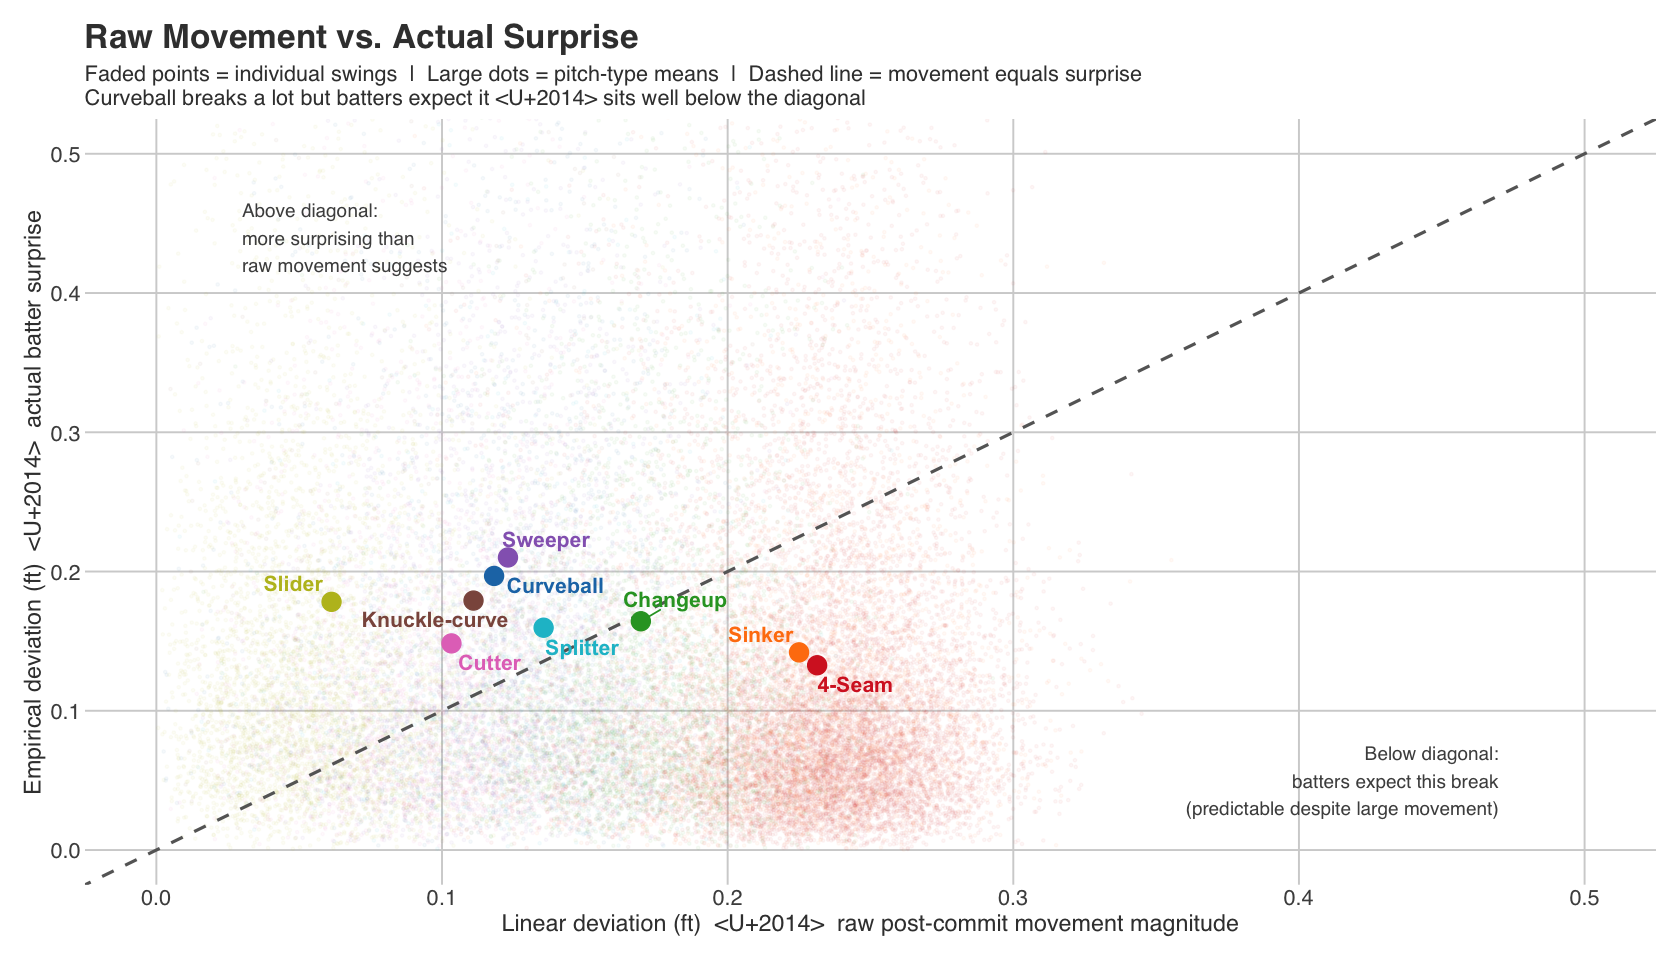

In [37]:
library(ggrepel)

ggplot() +
  geom_point(
    data = pc_sample |> filter(!is.na(emp_dev_total), !is.na(lin_dev_total)),
    aes(x = lin_dev_total, y = emp_dev_total, color = pitch_type),
    alpha = 0.04, size = 0.6, show.legend = FALSE
  ) +
  geom_abline(slope = 1, intercept = 0,
              linetype = "dashed", color = "grey40", linewidth = 0.9) +
  annotate("text", x = 0.03, y = 0.44,
           label = "Above diagonal:\nmore surprising than\nraw movement suggests",
           hjust = 0, size = 4, color = "grey30", lineheight = 1.2) +
  annotate("text", x = 0.47, y = 0.05,
           label = "Below diagonal:\nbatters expect this break\n(predictable despite large movement)",
           hjust = 1, size = 4, color = "grey30", lineheight = 1.2) +
  geom_point(
    data = pc_deception,
    aes(x = mean_lin_dev, y = mean_emp_dev, color = pitch_type),
    size = 5
  ) +
  geom_text_repel(
    data = pc_deception,
    aes(x = mean_lin_dev, y = mean_emp_dev, label = pitch_name, color = pitch_type),
    size = 4.5, fontface = "bold", show.legend = FALSE,
    box.padding = 0.4, point.padding = 0.3
  ) +
  scale_color_manual(values = PITCH_COLORS, guide = "none") +
  coord_cartesian(xlim = c(0, 0.5), ylim = c(0, 0.5)) +
  labs(
    title = "Raw Movement vs. Actual Surprise",
    subtitle = "Faded points = individual swings  |  Large dots = pitch-type means  |  Dashed line = movement equals surprise\nCurveball breaks a lot but batters expect it — sits well below the diagonal",
    x = "Linear deviation (ft)  —  raw post-commit movement magnitude",
    y = "Empirical deviation (ft)  —  actual batter surprise"
  )

## Deception Ratio by Pitch Type

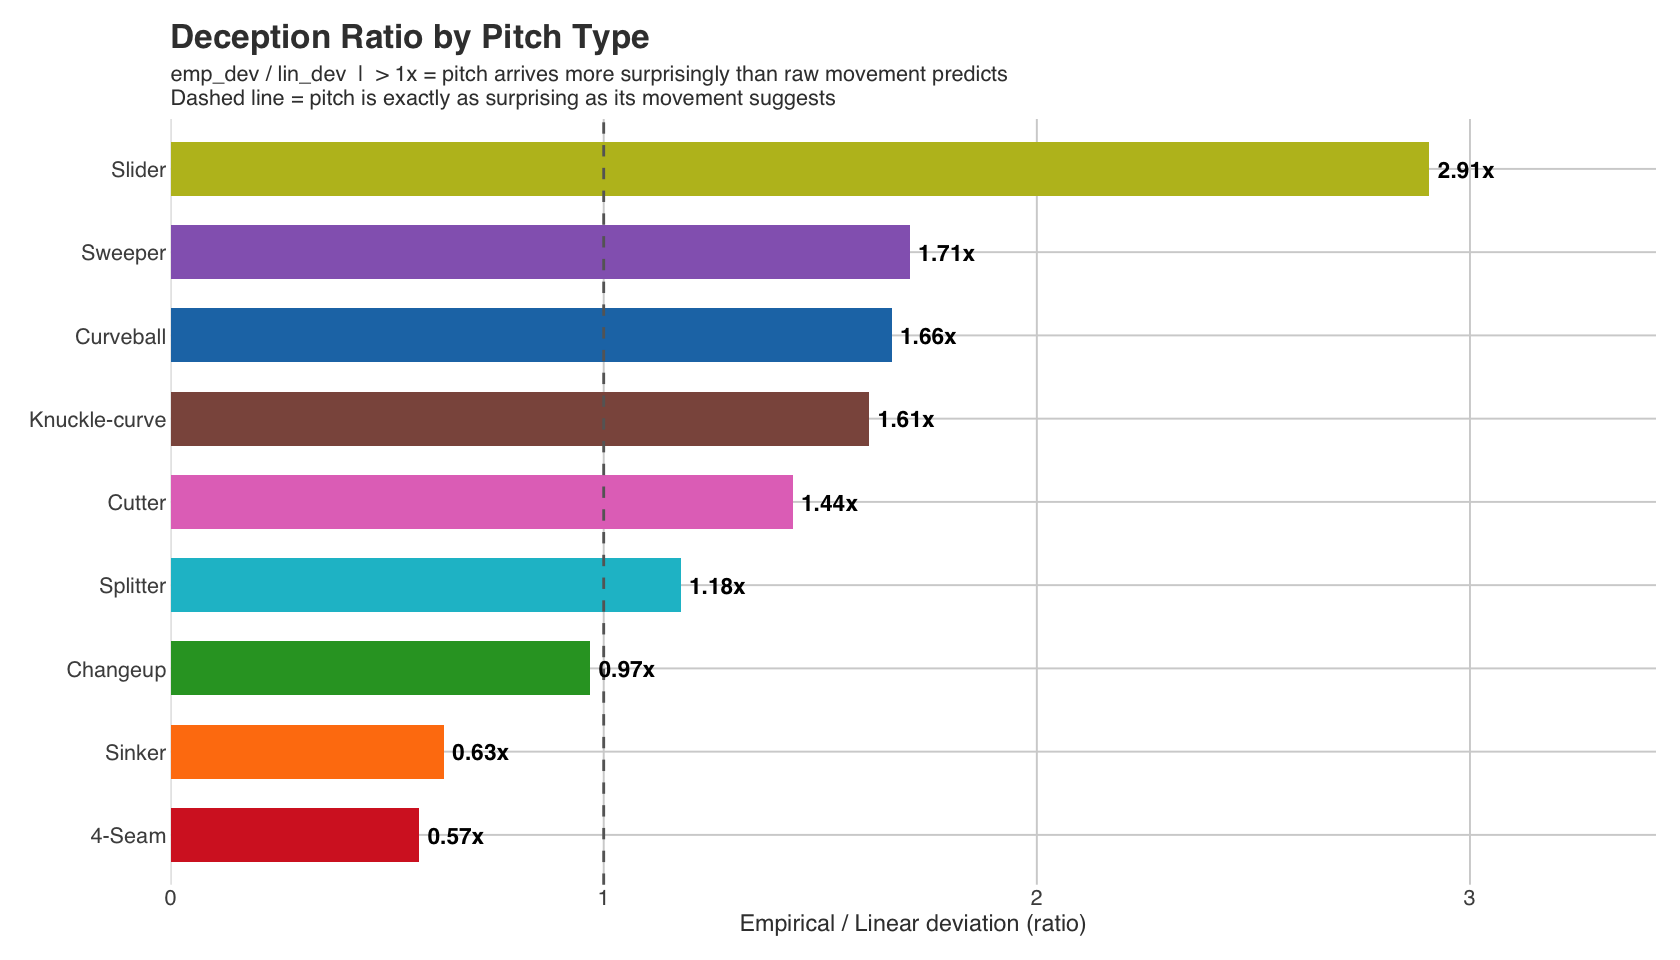

In [38]:
ggplot(pc_deception,
       aes(x = reorder(pitch_name, emp_lin_ratio),
           y = emp_lin_ratio, fill = pitch_type)) +
  geom_col(width = 0.65) +
  geom_hline(yintercept = 1, linetype = "dashed", color = "grey40", linewidth = 0.8) +
  geom_text(aes(label = sprintf("%.2fx", emp_lin_ratio)),
            hjust = -0.15, size = 4.8, fontface = "bold") +
  scale_fill_manual(values = PITCH_COLORS, guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.18))) +
  coord_flip() +
  labs(
    title    = "Deception Ratio by Pitch Type",
    subtitle = "emp_dev / lin_dev  |  > 1x = pitch arrives more surprisingly than raw movement predicts\nDashed line = pitch is exactly as surprising as its movement suggests",
    x        = NULL,
    y        = "Empirical / Linear deviation (ratio)"
  )

## Commit-Time Sensitivity

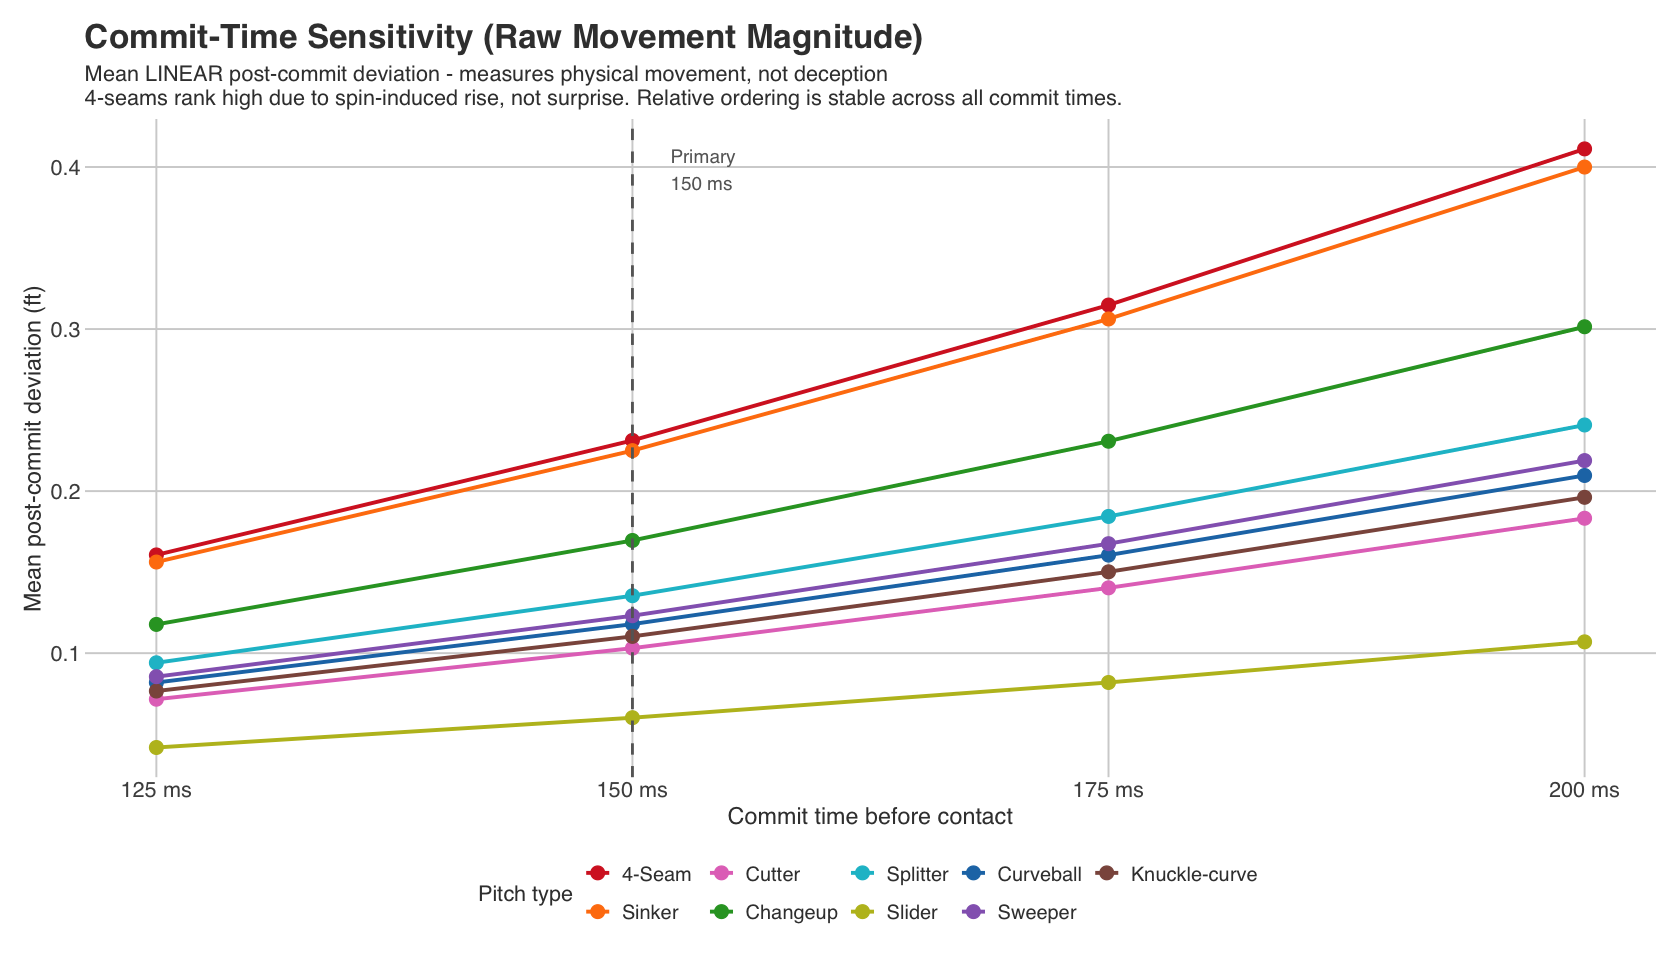

In [39]:
ggplot(pc_sens,
       aes(x = commit_ms, y = mean_dev,
           color = pitch_name, group = pitch_name)) +
  geom_line(linewidth = 1.1) +
  geom_point(size = 3.5) +
  geom_vline(xintercept = 150, linetype = "dashed",
             color = "grey40", linewidth = 0.8) +
  annotate("text", x = 152, y = max(pc_sens$mean_dev) * 0.97,
           label = "Primary\n150 ms", hjust = 0, size = 4, color = "grey40") +
  scale_color_manual(
    values = setNames(PITCH_COLORS[names(PITCH_NAMES)], unname(PITCH_NAMES)),
    name   = "Pitch type"
  ) +
  scale_x_continuous(breaks = c(125, 150, 175, 200),
                     labels = c("125 ms", "150 ms", "175 ms", "200 ms")) +
  labs(
    title    = "Commit-Time Sensitivity (Raw Movement Magnitude)",
    subtitle = "Mean LINEAR post-commit deviation - measures physical movement, not deception\n4-seams rank high due to spin-induced rise, not surprise. Relative ordering is stable across all commit times.",
    x        = "Commit time before contact",
    y        = "Mean post-commit deviation (ft)"
  )

## Late Movement by Count

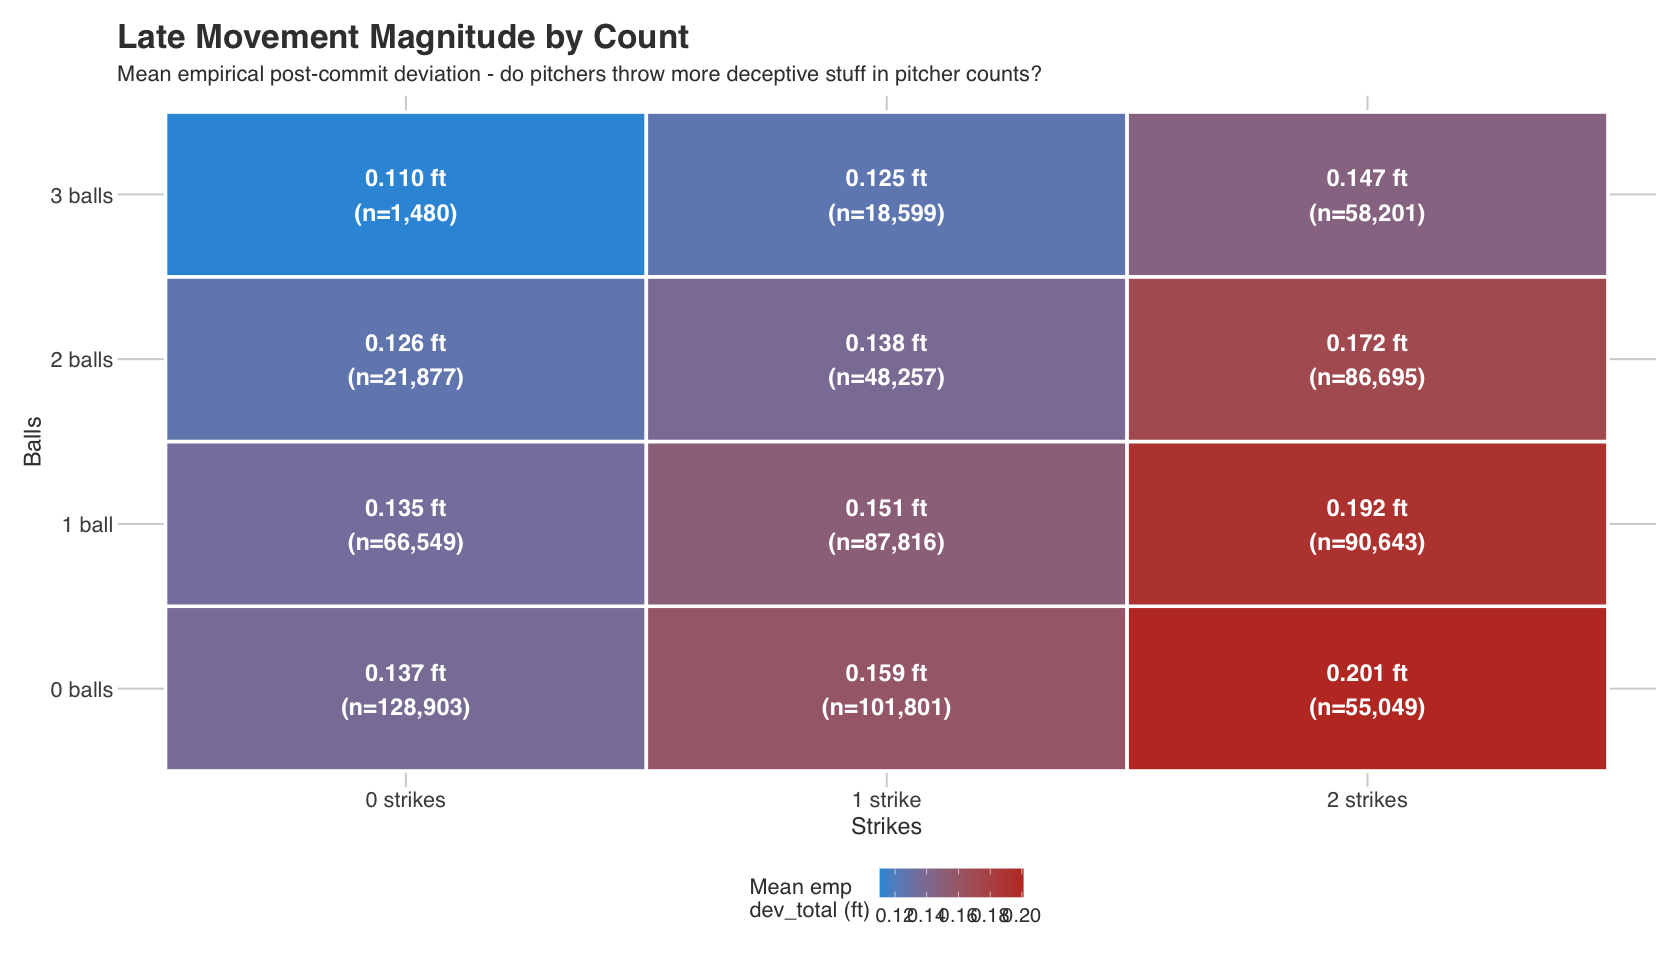

In [40]:
pc_count_dev |>
  mutate(
    label = sprintf("%.3f ft\n(n=%s)",
                    mean_emp_dev,
                    formatC(n, format = "d", big.mark = ","))
  ) |>
  ggplot(aes(x = factor(strikes), y = factor(balls), fill = mean_emp_dev)) +
  geom_tile(color = "white", linewidth = 1) +
  geom_text(aes(label = label),
            size = 5, color = "white", fontface = "bold", lineheight = 1.2) +
  scale_fill_gradient(
    low  = "#3498db", high = "#c0392b",
    name = "Mean emp\ndev_total (ft)"
  ) +
  scale_x_discrete(labels = c("0 strikes", "1 strike", "2 strikes")) +
  scale_y_discrete(labels = c("0 balls", "1 ball", "2 balls", "3 balls")) +
  labs(
    title    = "Late Movement Magnitude by Count",
    subtitle = "Mean empirical post-commit deviation - do pitchers throw more deceptive stuff in pitcher counts?",
    x        = "Strikes",
    y        = "Balls"
  )